# 02 — Data Cleaning Decisions & Exploratory Data Analysis (EDA)

This notebook documents cleaning decisions on **NSL-KDD** (`KDDTrain+` and `KDDTest+`), generates **5 Matplotlib/Seaborn visualisations** saved to `reports/figures/`, and identifies redundant features (`constant` and `|r| > 0.90` pairs on the 80% training split only) to guide Stage 2 Experiment E2 without data leakage.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import FEATURE_COLUMNS, FIGURES_DIR, NUMERIC_COLUMNS, RANDOM_SEED
from src.load_data import load_train_test_splits
from src.preprocess import find_redundant_features, make_train_val_split

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

train_df, test_df = load_train_test_splits()
print(f"Loaded KDDTrain+: {train_df.shape} | KDDTest+: {test_df.shape}")

Loaded KDDTrain+: (125973, 45) | KDDTest+: (22544, 45)


## 1. Data Cleaning & Feature-Selection Diagnostics

We verify missing values, duplicate rows, heavy skewness in volume features (`src_bytes`, `dst_bytes`, `duration`), constant columns, and collinear pairs (computed strictly on the 80% training split so validation and test data remain completely untouched).

In [2]:
# 1. Missing value check (kept in pipeline via SimpleImputer for unseen inference inputs)
print("Missing values (train / test):", int(train_df.isna().sum().sum()), "/", int(test_df.isna().sum().sum()))

# 2. Duplicate check before deciding whether to drop
print("Exact full-row duplicates (train / test):", int(train_df.duplicated().sum()), "/", int(test_df.duplicated().sum()))
print("41-feature duplicates (train / test):", int(train_df.duplicated(subset=FEATURE_COLUMNS).sum()), "/", int(test_df.duplicated(subset=FEATURE_COLUMNS).sum()))

# 3. Skewness of key continuous volume/duration features
skew_cols = ["duration", "src_bytes", "dst_bytes", "count", "serror_rate", "dst_host_srv_count"]
print("\nSkewness in KDDTrain+:")
print(train_df[skew_cols].skew().round(2).to_string())

# 4. Constant and high-correlation features (80% train split ONLY to prevent leakage)
X_tr, X_val, y_tr, y_val = make_train_val_split(train_df)
redundant = find_redundant_features(X_tr, corr_threshold=0.90)
print("\nConstant features (80% train):", redundant["constant_cols"])
print("High-correlation features flagged for removal in E2 (|r| > 0.90):", redundant["correlated_cols"])
print(f"Total flagged for E2 removal: {len(redundant['drop_cols'])} | Remaining features: {len(redundant['kept_features'])}")

Missing values (train / test): 0 / 0
Exact full-row duplicates (train / test): 0 / 0
41-feature duplicates (train / test): 16 / 57

Skewness in KDDTrain+:
duration               11.88
src_bytes             190.67
dst_bytes             290.05
count                   1.51
serror_rate             0.96
dst_host_srv_count      0.28

Constant features (80% train): ['num_outbound_cmds']
High-correlation features flagged for removal in E2 (|r| > 0.90): ['num_root', 'srv_serror_rate', 'srv_rerror_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
Total flagged for E2 removal: 8 | Remaining features: 33


**Documented Cleaning Decisions:**
1. **Missing values:** Both `KDDTrain+` and `KDDTest+` contain `0` missing entries. We retain explicit validation in `src/load_data.py` and `SimpleImputer` inside `src/preprocess.py` so corrupted or incomplete uploaded CSVs never fail silently.
2. **Duplicates:** There are `0` exact full-row duplicates and `0` `(feature + attack_type)` duplicates within `KDDTrain+`, and `16` feature-only duplicates (a negligible fraction of 125,973 rows). We preserve the official benchmark splits intact for fair comparison with published NSL-KDD literature.
3. **Skewed volume features:** `src_bytes` (skew = `190.67`), `dst_bytes` (skew = `290.05`), and `duration` (skew = `11.88`) are heavily right-skewed. We keep raw values for tree-based models (Random Forest) and apply `StandardScaler` inside the pipeline for Logistic Regression.
4. **Constant & metadata columns:** `num_outbound_cmds` is constant (`0` everywhere) and dropped in feature-pruned experiments (E2). `difficulty` and raw `attack_type` are always excluded from `X`.

## 2. Chart 1 — Class Distribution in Train vs. Official Test Split

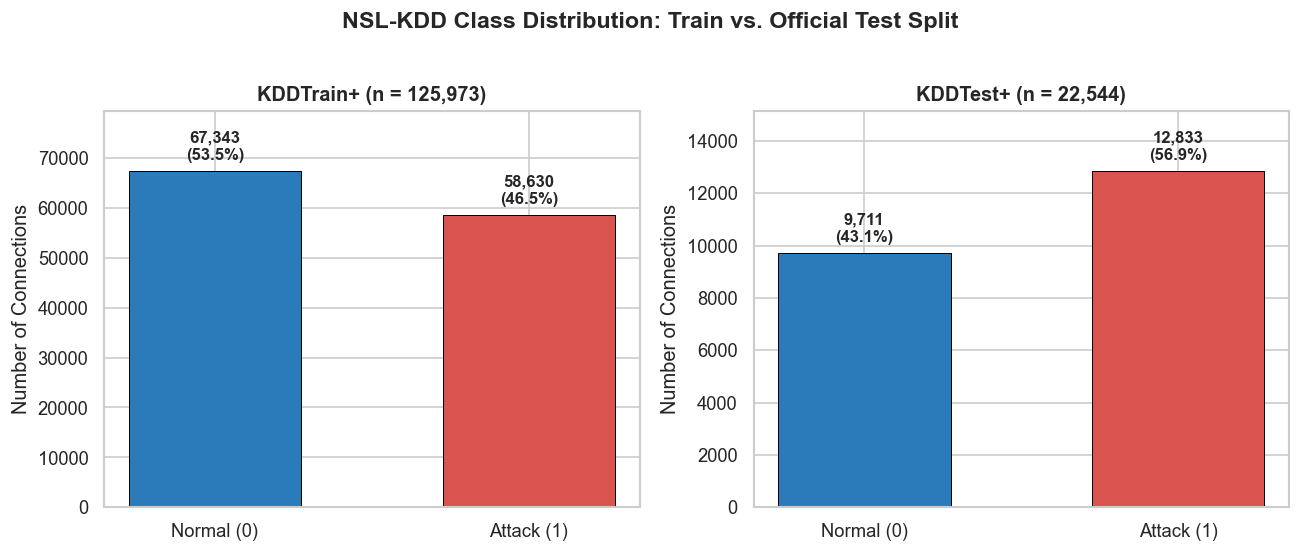

In [3]:
tr_counts = train_df["label"].value_counts().sort_index()
te_counts = test_df["label"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = ["#2b7bba", "#d9534f"]
labels_txt = ["Normal (0)", "Attack (1)"]

for ax, counts, title in [
    (axes[0], tr_counts, f"KDDTrain+ (n = {len(train_df):,})"),
    (axes[1], te_counts, f"KDDTest+ (n = {len(test_df):,})"),
]:
    bars = ax.bar(labels_txt, [counts[0], counts[1]], color=colors, width=0.55, edgecolor="black", linewidth=0.6)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Number of Connections")
    ax.set_ylim(0, max(counts.values) * 1.18)
    total = counts.sum()
    for bar, val in zip(bars, [counts[0], counts[1]]):
        pct = val / total * 100
        ax.text(bar.get_x() + bar.get_width() / 2, val + max(counts.values) * 0.025,
                f"{val:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

fig.suptitle("NSL-KDD Class Distribution: Train vs. Official Test Split", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_balance_train_vs_test.png", bbox_inches="tight", dpi=140)
plt.show()

**Interpretation (Chart 1):**
`KDDTrain+` is moderately balanced, containing **67,343 normal (53.5%)** and **58,630 attack (46.54%)** connections, so stratified train/validation splitting works well without aggressive resampling. By contrast, `KDDTest+` flips the majority class to **12,833 attack (56.92%)** versus **9,711 normal (43.1%)** connections. This prior-probability shift reinforces why raw accuracy alone is misleading and why attack recall, attack F1, and macro F1 should be tracked together.

## 3. Chart 2 — Top Attack Types in Train vs. Test (Highlighting Unseen Test Attacks)

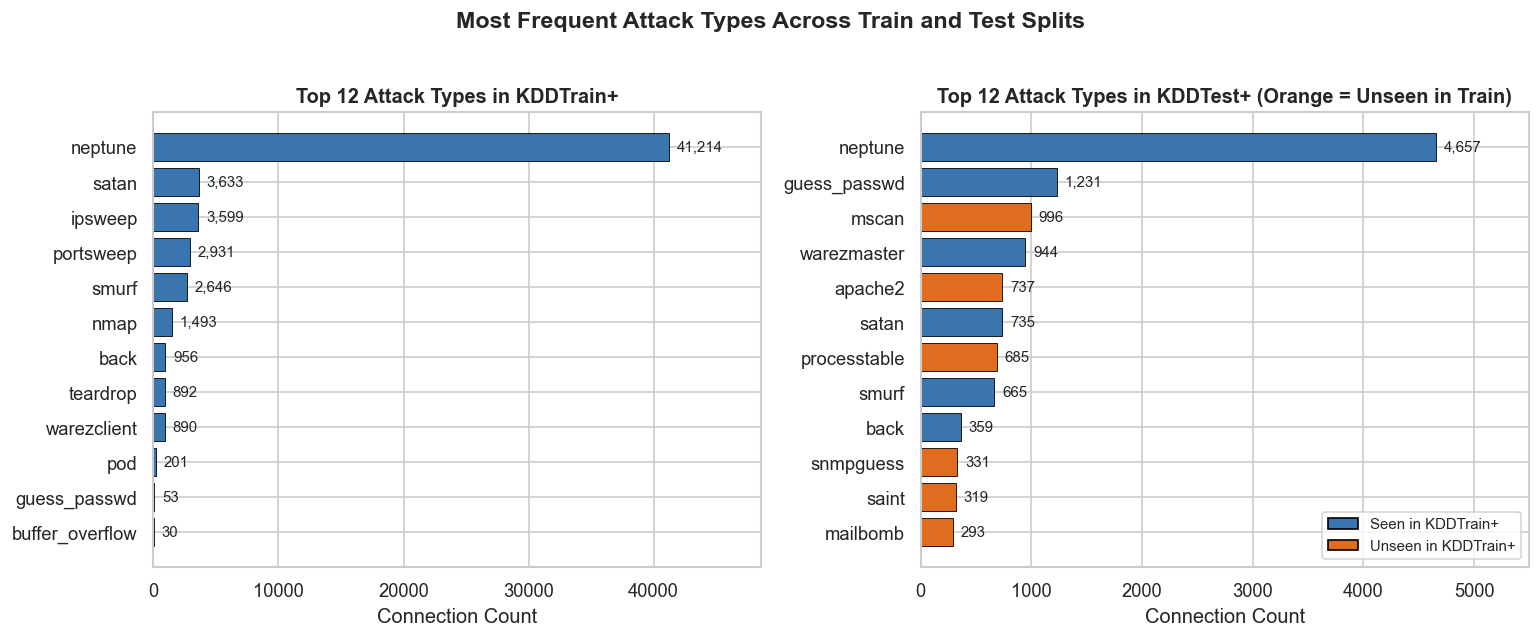

In [4]:
train_attacks = set(train_df["attack_type"].unique()) - {"normal"}
test_attacks = set(test_df["attack_type"].unique()) - {"normal"}
unseen_in_train = sorted(test_attacks - train_attacks)

tr_atk = train_df[train_df["attack_type"] != "normal"]["attack_type"].value_counts().head(12).sort_values()
te_atk = test_df[test_df["attack_type"] != "normal"]["attack_type"].value_counts().head(12).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
axes[0].barh(tr_atk.index, tr_atk.values, color="#3b75af", edgecolor="black", linewidth=0.5)
axes[0].set_title("Top 12 Attack Types in KDDTrain+", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Connection Count")
for i, v in enumerate(tr_atk.values):
    axes[0].text(v + tr_atk.max() * 0.015, i, f"{v:,}", va="center", fontsize=9)
axes[0].set_xlim(0, tr_atk.max() * 1.18)

bar_colors = ["#e06c1f" if atk in unseen_in_train else "#3b75af" for atk in te_atk.index]
axes[1].barh(te_atk.index, te_atk.values, color=bar_colors, edgecolor="black", linewidth=0.5)
axes[1].set_title("Top 12 Attack Types in KDDTest+ (Orange = Unseen in Train)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Connection Count")
for i, v in enumerate(te_atk.values):
    axes[1].text(v + te_atk.max() * 0.015, i, f"{v:,}", va="center", fontsize=9)
axes[1].set_xlim(0, te_atk.max() * 1.18)
axes[1].legend(handles=[
    Patch(facecolor="#3b75af", edgecolor="black", label="Seen in KDDTrain+"),
    Patch(facecolor="#e06c1f", edgecolor="black", label="Unseen in KDDTrain+"),
], loc="lower right", frameon=True, fontsize=9)

fig.suptitle("Most Frequent Attack Types Across Train and Test Splits", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_top_attack_types_train_vs_test.png", bbox_inches="tight", dpi=140)
plt.show()

**Interpretation (Chart 2):**
In `KDDTrain+`, `neptune` alone dominates the attack distribution (`41,214` connections), followed by `satan` (`3,633`), `ipsweep` (`3,599`), and `portsweep` (`2,931`). In `KDDTest+`, although `neptune` (`4,657`) remains the single largest attack and `guess_passwd` surges dramatically (`1,231` rows vs. rare presence in train), **17 entirely unseen attack types** appear—led by `mscan` (`996`), `apache2` (`737`), `processtable` (`685`), `snmpguess` (`331`), `saint` (`319`), and `mailbomb` (`293`)—totaling **3,750 rows (29.22% of all test attacks)**. Because supervised classifiers have never seen these 17 attack signatures during training, test recall is expected to be substantially lower than validation recall.

## 4. Chart 3 — Box Plots of Key Numeric Features Split by Class

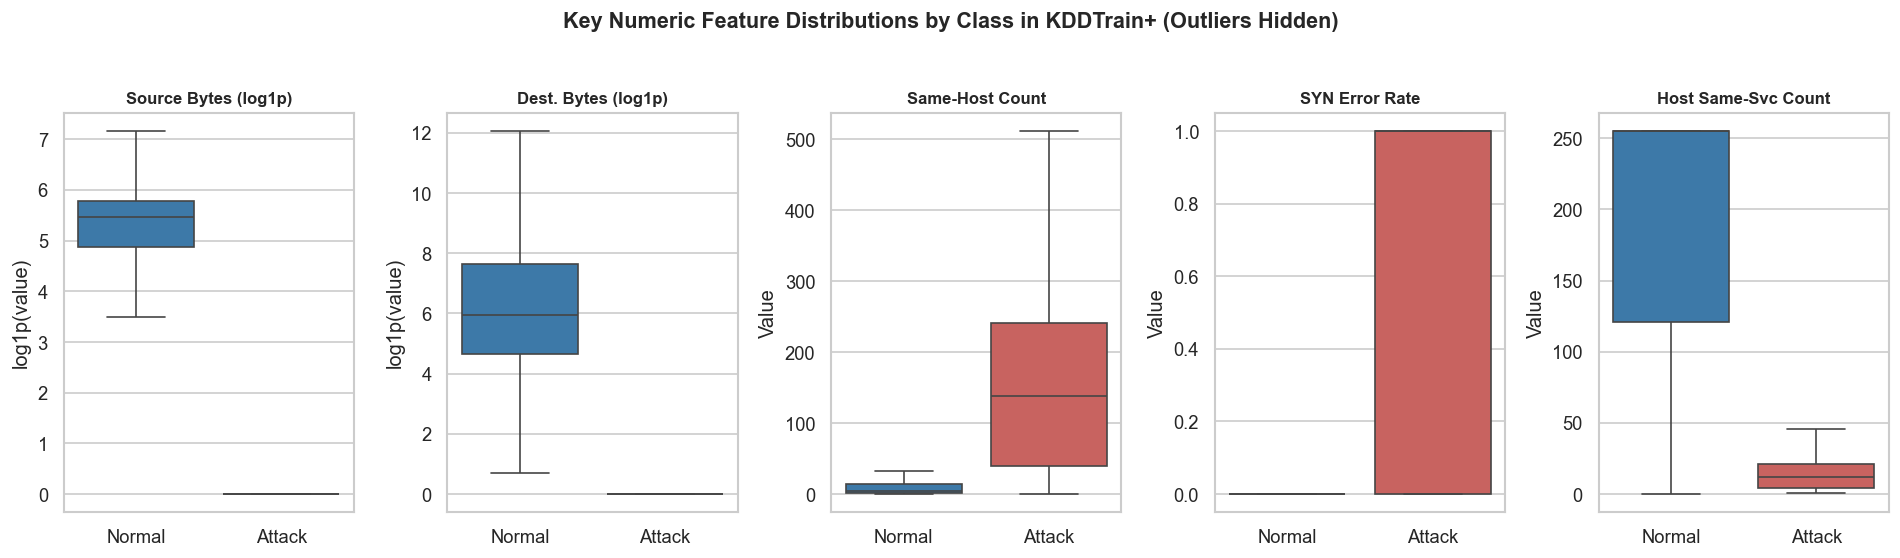

In [5]:
box_features = [
    ("src_bytes", True, "Source Bytes (log1p)"),
    ("dst_bytes", True, "Dest. Bytes (log1p)"),
    ("count", False, "Same-Host Count"),
    ("serror_rate", False, "SYN Error Rate"),
    ("dst_host_srv_count", False, "Host Same-Svc Count"),
]

fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))
plot_df = train_df[["label"] + [f[0] for f in box_features]].copy()
plot_df["Class"] = plot_df["label"].map({0: "Normal", 1: "Attack"})

for ax, (col, use_log, subtitle) in zip(axes, box_features):
    y_vals = np.log1p(plot_df[col].clip(lower=0)) if use_log else plot_df[col]
    temp = pd.DataFrame({"Class": plot_df["Class"], "Value": y_vals})
    sns.boxplot(
        data=temp, x="Class", y="Value", hue="Class",
        palette={"Normal": "#2b7bba", "Attack": "#d9534f"},
        legend=False, showfliers=False, ax=ax,
    )
    ax.set_title(subtitle, fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("log1p(value)" if use_log else "Value")

fig.suptitle("Key Numeric Feature Distributions by Class in KDDTrain+ (Outliers Hidden)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "03_key_numeric_boxplots.png", bbox_inches="tight", dpi=140)
plt.show()

**Interpretation (Chart 3):**
Clear class separation appears across traffic volume, connection frequency, and TCP error features. Normal traffic transfers substantially more bytes (median `src_bytes = 233.0`, median `dst_bytes = 379.0`) and maintains higher `dst_host_srv_count` (median `255.0` vs. `12.0` for attacks), whereas attack connections exhibit much higher `count` (median `138.0` vs. `4.0`) and elevated `serror_rate` (mean `0.596` vs. `0.013`), consistent with SYN-flood DoS and port-scanning behavior. Because `src_bytes` and `dst_bytes` span multiple orders of magnitude, feature scaling is critical for linear models while tree ensembles can split naturally on raw thresholds.

## 5. Chart 4 — Correlation Heatmap of Non-Constant Numeric Features

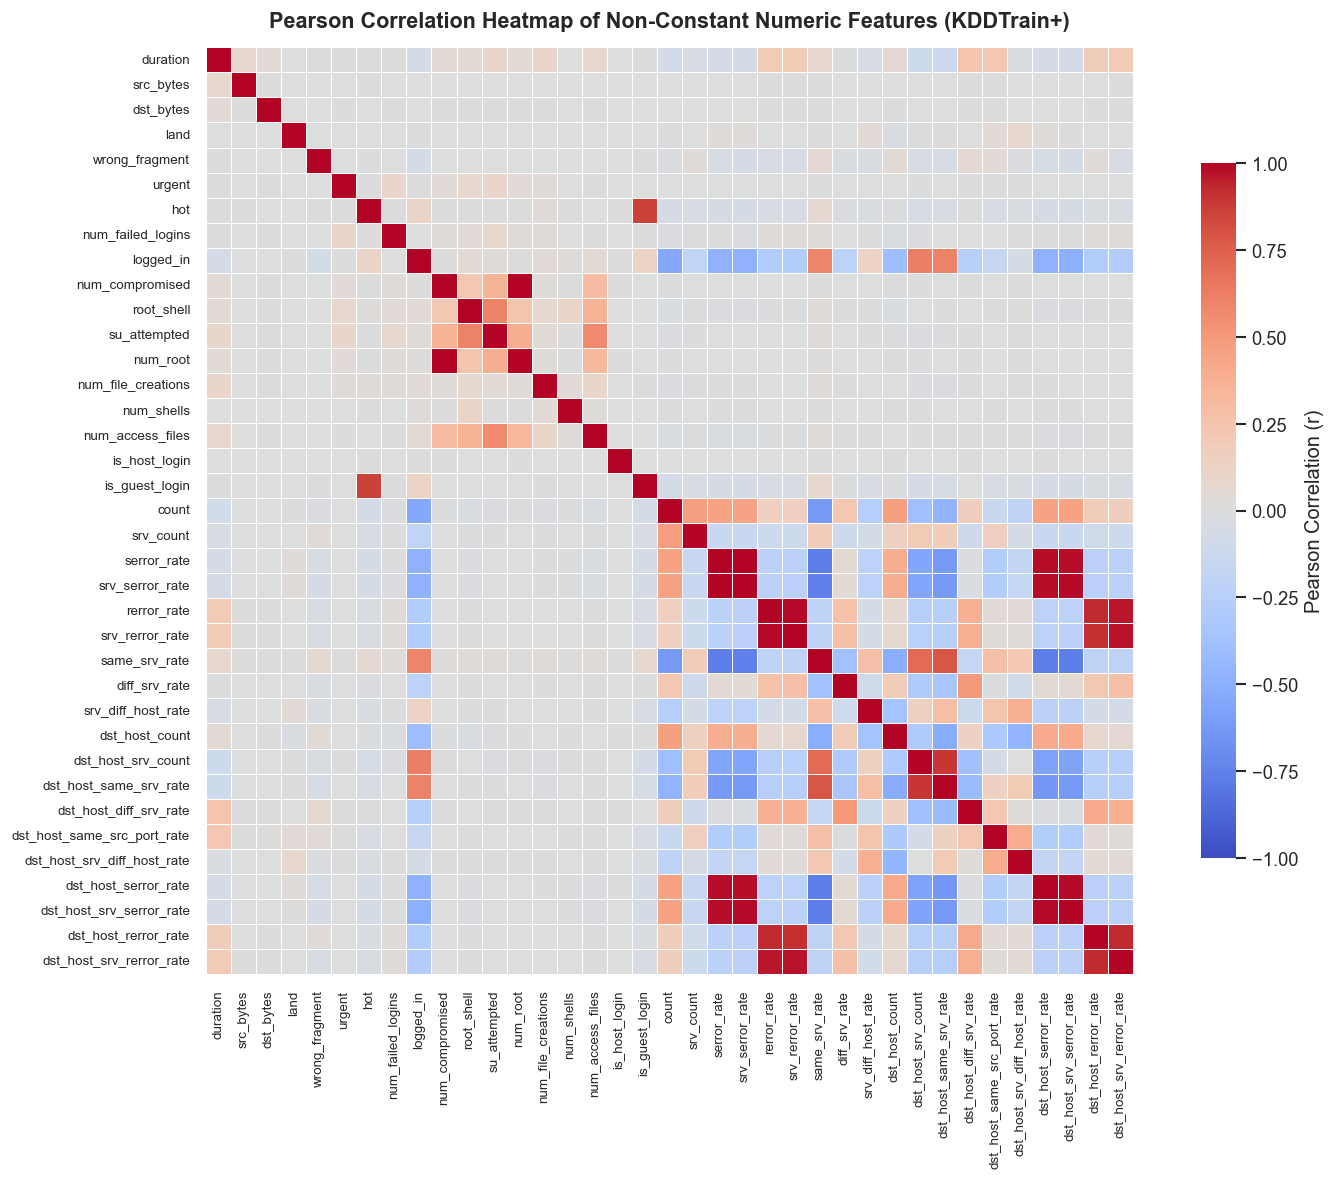

In [6]:
non_const_num = [c for c in NUMERIC_COLUMNS if train_df[c].nunique() > 1]
corr_full = train_df[non_const_num].corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr_full, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.3,
    cbar_kws={"shrink": 0.75, "label": "Pearson Correlation (r)"}, ax=ax,
)
ax.set_title("Pearson Correlation Heatmap of Non-Constant Numeric Features (KDDTrain+)", fontsize=13, fontweight="bold", pad=12)
ax.tick_params(axis="x", labelsize=8, rotation=90)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_numeric_correlation_heatmap.png", bbox_inches="tight", dpi=140)
plt.show()

**Interpretation (Chart 4):**
Strong positive correlation clusters appear among TCP SYN-error rates (`serror_rate`, `srv_serror_rate`, `dst_host_serror_rate`, `dst_host_srv_serror_rate`), REJ-error rates (`rerror_rate`, `srv_rerror_rate`, `dst_host_rerror_rate`, `dst_host_srv_rerror_rate`), and compromised-host counts (`num_compromised` with `num_root`). On the 80% training split, **13 feature pairs exceed `|r| > 0.90`**, flagging **7 redundant numeric columns** (`['num_root', 'srv_serror_rate', 'srv_rerror_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']`) plus constant `num_outbound_cmds` for removal in Experiment E2:
  - `num_compromised` vs. `num_root` ($r = 0.9992$)
  - `serror_rate` vs. `srv_serror_rate` ($r = 0.9934$)
  - `serror_rate` vs. `dst_host_serror_rate` ($r = 0.9793$)
  - `serror_rate` vs. `dst_host_srv_serror_rate` ($r = 0.981$)
  - `srv_serror_rate` vs. `dst_host_serror_rate` ($r = 0.9779$)
  - `srv_serror_rate` vs. `dst_host_srv_serror_rate` ($r = 0.9862$)
  - `rerror_rate` vs. `srv_rerror_rate` ($r = 0.9894$)
  - `rerror_rate` vs. `dst_host_rerror_rate` ($r = 0.9272$)
  - `rerror_rate` vs. `dst_host_srv_rerror_rate` ($r = 0.9652$)
  - `srv_rerror_rate` vs. `dst_host_rerror_rate` ($r = 0.9188$)
  - `srv_rerror_rate` vs. `dst_host_srv_rerror_rate` ($r = 0.9709$)
  - `dst_host_serror_rate` vs. `dst_host_srv_serror_rate` ($r = 0.9852$)
  - `dst_host_rerror_rate` vs. `dst_host_srv_rerror_rate` ($r = 0.9249$)

## 6. Chart 5 — Categorical Signal: Attack Rate by Protocol Type & Top TCP Flags

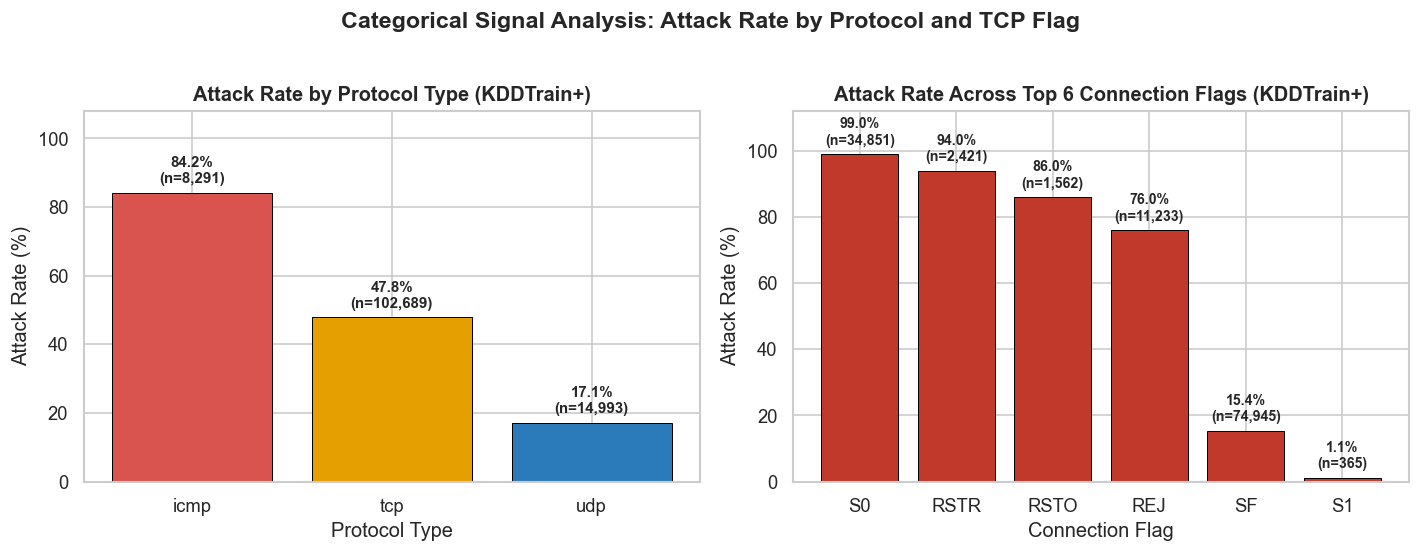

In [7]:
proto_stats = train_df.groupby("protocol_type")["label"].agg(count="count", attack_rate="mean").reset_index().sort_values("attack_rate", ascending=False)
flag_stats = train_df.groupby("flag")["label"].agg(count="count", attack_rate="mean").sort_values("count", ascending=False).head(6).reset_index().sort_values("attack_rate", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bars1 = axes[0].bar(proto_stats["protocol_type"], proto_stats["attack_rate"] * 100, color=["#d9534f", "#e69f00", "#2b7bba"], edgecolor="black", linewidth=0.6)
axes[0].set_title("Attack Rate by Protocol Type (KDDTrain+)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Protocol Type")
axes[0].set_ylabel("Attack Rate (%)")
axes[0].set_ylim(0, 108)
for bar, (_, row) in zip(bars1, proto_stats.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width() / 2, row["attack_rate"] * 100 + 2,
                 f"{row['attack_rate']*100:.1f}%\n(n={int(row['count']):,})", ha="center", va="bottom", fontsize=9, fontweight="bold")

bars2 = axes[1].bar(flag_stats["flag"], flag_stats["attack_rate"] * 100, color="#c0392b", edgecolor="black", linewidth=0.6)
axes[1].set_title("Attack Rate Across Top 6 Connection Flags (KDDTrain+)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Connection Flag")
axes[1].set_ylabel("Attack Rate (%)")
axes[1].set_ylim(0, 112)
for bar, (_, row) in zip(bars2, flag_stats.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width() / 2, row["attack_rate"] * 100 + 2,
                 f"{row['attack_rate']*100:.1f}%\n(n={int(row['count']):,})", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

fig.suptitle("Categorical Signal Analysis: Attack Rate by Protocol and TCP Flag", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_attack_rate_by_protocol_and_flag.png", bbox_inches="tight", dpi=140)
plt.show()

**Interpretation (Chart 5):**
Categorical network fields carry strong predictive signal. `icmp` connections have the highest attack rate (**84.2%**, `n = 8,291`, driven by `smurf` and `ipsweep`), followed by `tcp` (**47.8%**, `n = 102,689`) and `udp` (**17.1%**, `n = 14,993`). Similarly, abnormal TCP handshake termination flags (`S0` at **99.0%**, `RSTR` at **94.0%**, `RSTO` at **86.0%**, and `REJ` at **76.0%**) are overwhelmingly associated with attacks, whereas normal completed connections (`SF`) have only a **15.4%** attack rate (`S1` is **1.1%**), confirming that one-hot encoding `protocol_type`, `flag`, and `service` adds strong discriminative power.